Saving 360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm.jpg to 360_F_611384969_mnfmR31h3922XIlWYYNQYXpUIIfeXfIm (7).jpg
Image loaded successfully!
Image shape: (360, 540)


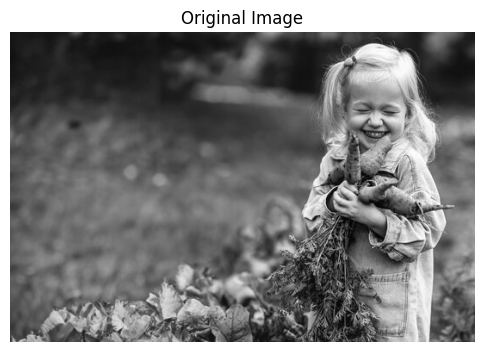

In [40]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

if not uploaded:
    print("No file was uploaded. Please run the cell again and select an image file.")
else:
    filename = list(uploaded.keys())[0]

    original = cv2.imdecode(
        np.frombuffer(uploaded[filename], np.uint8),
        cv2.IMREAD_GRAYSCALE
    )

    if original is None:
        print("Error: The uploaded file could not be decoded as an image. Please upload a valid image (PNG/JPG).")
    else:
        print("Image loaded successfully!")
        print("Image shape:", original.shape)

        plt.figure(figsize=(6, 5))
        plt.imshow(original, cmap='gray')
        plt.title("Original Image")
        plt.axis("off")
        plt.show()

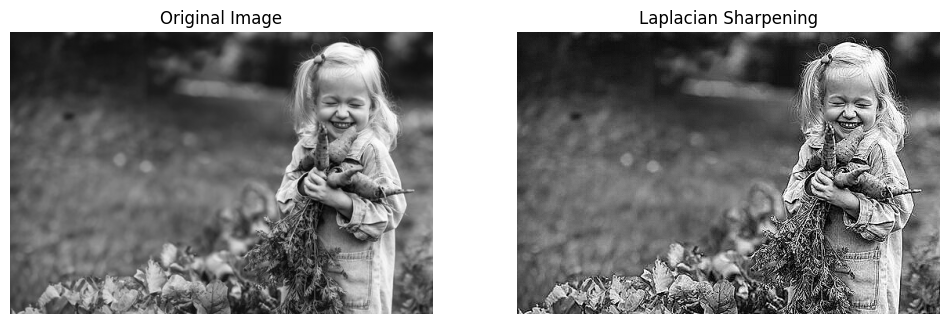

In [41]:

import cv2
import numpy as np
import matplotlib.pyplot as plt


kernel = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)


sharp_lap = cv2.filter2D(
    original,
    ddepth=-1,
    kernel=kernel
)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original, cmap='gray')
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sharp_lap, cmap='gray')
plt.title("Laplacian Sharpening")
plt.axis("off")

plt.show()


Number of negative gradient pixels: 87638


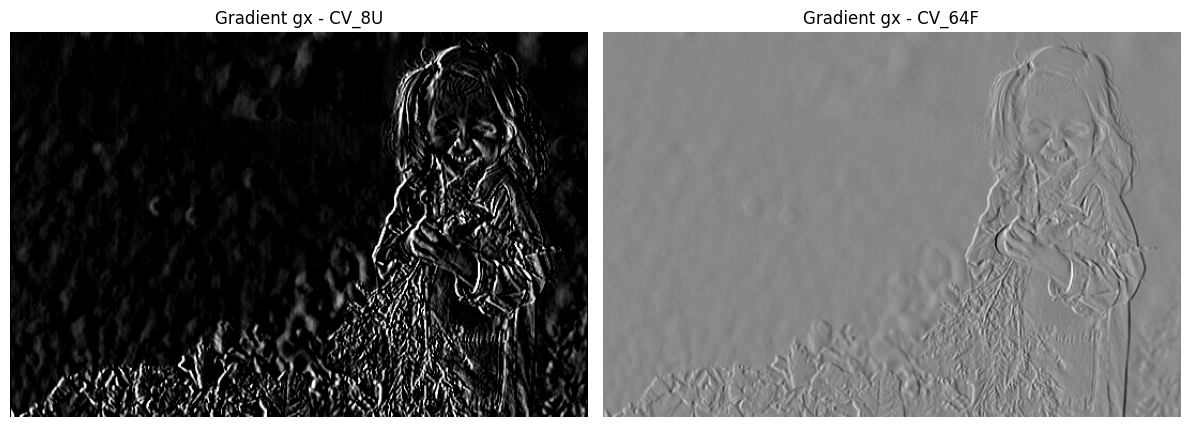

In [42]:

import cv2
import numpy as np
import matplotlib.pyplot as plt




gx_8u = cv2.Sobel(
    original,
    cv2.CV_8U,
    1, 0,
    ksize=3
)

gx_64f = cv2.Sobel(
    original,
    cv2.CV_64F,
    1, 0,
    ksize=3
)


negative_pixels = np.sum(gx_64f < 0)

print("Number of negative gradient pixels:", negative_pixels)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(gx_8u, cmap='gray')
plt.title("Gradient gx - CV_8U")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gx_64f, cmap='gray')
plt.title("Gradient gx - CV_64F")
plt.axis("off")

plt.tight_layout()
plt.show()


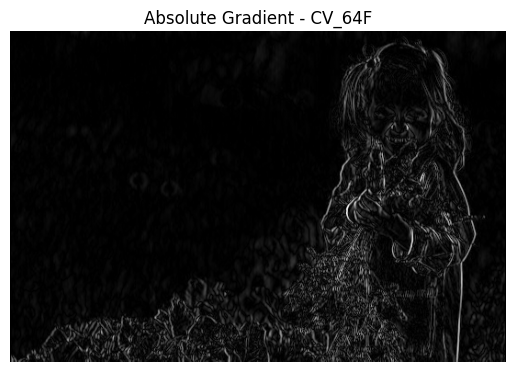

In [43]:
plt.imshow(np.abs(gx_64f), cmap='gray')
plt.title("Absolute Gradient - CV_64F")
plt.axis("off")
plt.show()

80th percentile threshold: 92.78
90th percentile threshold: 166.31
95th percentile threshold: 243.26


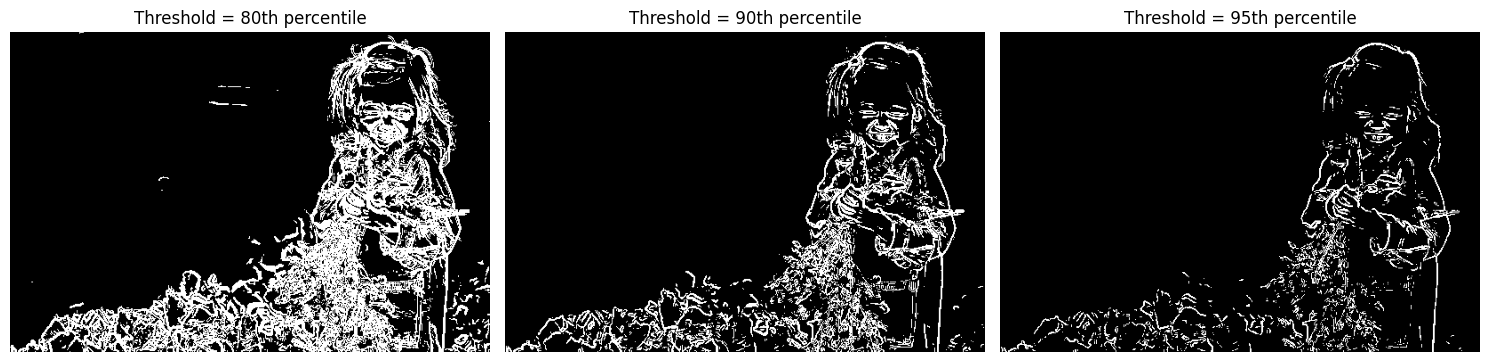

In [44]:


gy = cv2.Sobel(
    original,
    cv2.CV_64F,
    0, 1,
    ksize=3
)


mag = np.sqrt(gx_64f**2 + gy**2)


percentiles = [80, 90, 95]

plt.figure(figsize=(15, 5))

for i, p in enumerate(percentiles):

    threshold = np.percentile(mag, p)


    edge_map = (mag >= threshold).astype(np.uint8) * 255

    print(f"{p}th percentile threshold: {threshold:.2f}")

    plt.subplot(1, 3, i + 1)
    plt.imshow(edge_map, cmap='gray')
    plt.title(f"Threshold = {p}th percentile")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [45]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Please upload 'original.png' and 'damaged.png'.")
uploaded = files.upload()

# Helper function to decode uploaded images safely
def get_uploaded_image(target_name):
    for name, data in uploaded.items():
        if target_name in name.lower():
            return cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_GRAYSCALE)
    return None

original = get_uploaded_image("original")
damaged = get_uploaded_image("damaged")

if original is None or damaged is None:
    print("Error: Both 'original' and 'damaged' images must be uploaded to proceed.")
else:
    print("Original shape:", original.shape)
    print("Damaged shape:", damaged.shape)

Please upload 'original.png' and 'damaged.png'.


Saving pngtree-distress-or-dirt-and-damage-effect-concept-png-image_7117673.png to pngtree-distress-or-dirt-and-damage-effect-concept-png-image_7117673 (1).png
Error: Both 'original' and 'damaged' images must be uploaded to proceed.


In [46]:

def calculate_psnr(original, restored):

    mse = np.mean(
        (original.astype(np.float64) -
         restored.astype(np.float64)) ** 2
    )

    if mse == 0:
        return float("inf")

    return 10 * np.log10(255**2 / mse)


In [47]:

def rescue(img):


    median = cv2.medianBlur(img, 3)


    denoised = cv2.fastNlMeansDenoising(
        median,
        None,
        h=7,
        templateWindowSize=7,
        searchWindowSize=21
    )


    clahe = cv2.createCLAHE(
        clipLimit=1.2,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(denoised)


    blurred = cv2.GaussianBlur(
        enhanced,
        (5, 5),
        0
    )

    sharp = cv2.addWeighted(
        enhanced, 1.35,
        blurred, -0.35,
        0
    )

    return sharp


In [48]:
# Check if the images exist in the current environment
if 'original' not in globals() or 'damaged' not in globals() or original is None or damaged is None:
    print("Error: 'original' or 'damaged' image is not loaded in memory.")
    print("Please go back to cell -cNRec5H_JEP, run it, and upload both images correctly.")
else:
    restored = rescue(damaged)

    psnr_damaged = calculate_psnr(original, damaged)
    psnr_restored = calculate_psnr(original, restored)
    psnr_original = calculate_psnr(original, original)

    print("Damaged PSNR:", round(psnr_damaged, 2), "dB")
    print("Restored PSNR:", round(psnr_restored, 2), "dB")
    print("Original PSNR:", round(psnr_original, 2), "dB")

    if psnr_restored >= 22:
        print("SUCCESS: Target PSNR of 22 dB achieved!")
    else:
        print("Target not reached yet. Tune the restoration parameters.")

Error: 'original' or 'damaged' image is not loaded in memory.
Please go back to cell -cNRec5H_JEP, run it, and upload both images correctly.


In [49]:

if 'original' not in globals() or 'damaged' not in globals() or 'restored' not in globals() or original is None or damaged is None or restored is None:
    print("Error: Cannot plot because images ('original', 'damaged', or 'restored') are not successfully loaded in memory.")
else:
    plt.figure(figsize=(16, 6))

    plt.subplot(1, 3, 1)
    plt.imshow(damaged, cmap='gray')
    plt.title(f"Damaged\nPSNR = {psnr_damaged:.2f} dB")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(restored, cmap='gray')
    plt.title(f"Rescue Result\nPSNR = {psnr_restored:.2f} dB")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(original, cmap='gray')
    plt.title(f"Original\nPSNR = {psnr_original:.2f} dB")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

Error: Cannot plot because images ('original', 'damaged', or 'restored') are not successfully loaded in memory.
